##### Note : This is just a skeletal summary of the project and the full version of approach and compliance framework could be shared later if required.

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
full_df = pd.read_csv("SAML-D.csv")

In [3]:
full_df.head(2)

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out


In [4]:
full_df.shape

(9504852, 12)

In [6]:
full_df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 9504852 entries, 0 to 9504851
Data columns (total 12 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   Time                    9504852 non-null  str    
 1   Date                    9504852 non-null  str    
 2   Sender_account          9504852 non-null  int64  
 3   Receiver_account        9504852 non-null  int64  
 4   Amount                  9504852 non-null  float64
 5   Payment_currency        9504852 non-null  str    
 6   Received_currency       9504852 non-null  str    
 7   Sender_bank_location    9504852 non-null  str    
 8   Receiver_bank_location  9504852 non-null  str    
 9   Payment_type            9504852 non-null  str    
 10  Is_laundering           9504852 non-null  int64  
 11  Laundering_type         9504852 non-null  str    
dtypes: float64(1), int64(3), str(8)
memory usage: 1.4 GB


In [7]:
full_df.isnull().sum()

Time                      0
Date                      0
Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Laundering_type           0
dtype: int64

In [8]:
full_df.duplicated().sum()

np.int64(0)

In [9]:
full_df['Is_laundering'].value_counts()

Is_laundering
0    9494979
1       9873
Name: count, dtype: int64

In [10]:
df_fraud = full_df[full_df['Is_laundering']==1]

In [11]:
df_fraud.shape

(9873, 12)

In [12]:
df_fraud.shape[0]

9873

In [13]:
df_non_fraud = full_df[full_df['Is_laundering']==0]

In [14]:
df_non_fraud_sample = df_non_fraud.sample(n=df_fraud.shape[0], random_state=42)

In [15]:
df_combined = pd.concat([df_fraud, df_non_fraud_sample], axis=0)

In [16]:
df_combined.shape

(19746, 12)

In [17]:
df_combined = df_combined.sample(frac=1, random_state=42).reset_index(drop=True)

In [18]:
df_combined.head(2)

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,07:40:08,2023-07-14,3187084517,8846937355,3788.78,UK pounds,UK pounds,UK,UK,Cash Deposit,1,Smurfing
1,22:04:14,2022-10-29,4851027632,9832274459,7377.62,UK pounds,Euro,UK,France,Cross-border,0,Normal_Fan_Out


In [20]:
df_combined_tab = pd.crosstab(index=df_combined['Laundering_type'],
                              columns=df_combined['Is_laundering']
                             )
df_combined_tab

Is_laundering,0,1
Laundering_type,,
Behavioural_Change_1,0,394
Behavioural_Change_2,0,345
Bipartite,0,383
Cash_Withdrawal,0,1334
Cycle,0,382
Deposit-Send,0,945
Fan_In,0,364
Fan_Out,0,237
Gather-Scatter,0,354


In [21]:
df_combined = df_combined.drop('Laundering_type', axis=1)

In [22]:
df_combined.head(2)

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering
0,07:40:08,2023-07-14,3187084517,8846937355,3788.78,UK pounds,UK pounds,UK,UK,Cash Deposit,1
1,22:04:14,2022-10-29,4851027632,9832274459,7377.62,UK pounds,Euro,UK,France,Cross-border,0


In [23]:
df_combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 19746 entries, 0 to 19745
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Time                    19746 non-null  str    
 1   Date                    19746 non-null  str    
 2   Sender_account          19746 non-null  int64  
 3   Receiver_account        19746 non-null  int64  
 4   Amount                  19746 non-null  float64
 5   Payment_currency        19746 non-null  str    
 6   Received_currency       19746 non-null  str    
 7   Sender_bank_location    19746 non-null  str    
 8   Receiver_bank_location  19746 non-null  str    
 9   Payment_type            19746 non-null  str    
 10  Is_laundering           19746 non-null  int64  
dtypes: float64(1), int64(3), str(7)
memory usage: 2.6 MB


## Ensemble Models

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

In [25]:
df_combined['Hour'] = df_combined['Time'].str[:2].astype(int)

In [26]:
df_combined['Date'] = pd.to_datetime(df_combined['Date'])

In [27]:
df_combined['Month'] = df_combined['Date'].dt.month

In [28]:
df_combined['Day_of_week'] = df_combined['Date'].dt.dayofweek

In [29]:
X_ensemble = df_combined.drop(columns = ['Time', 'Date', 'Sender_account', 'Receiver_account', 'Is_laundering'])

In [30]:
y_ensemble = df_combined['Is_laundering']

In [31]:
X_ensemble_encoded = pd.get_dummies(X_ensemble, columns=['Payment_currency', 'Received_currency', 
                                               'Sender_bank_location', 'Receiver_bank_location', 'Payment_type'],
                               drop_first=True).astype(int)

## Splitting the dataset into train and test datasets

In [32]:
from sklearn.model_selection import train_test_split

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X_ensemble_encoded, y_ensemble, test_size=0.20, stratify=y_ensemble, random_state=42)

In [34]:
from sklearn.preprocessing import RobustScaler

In [35]:
rc = RobustScaler()

In [36]:
X_train_ensemble_scaled = rc.fit_transform(X_train)

In [37]:
X_test_ensemble_scaled = rc.transform(X_test)

In [38]:
clf_lr = LogisticRegression(max_iter=1000, random_state=42)
clf_rf = RandomForestClassifier(random_state=42)
clf_xgb = XGBClassifier(random_state=42)
clf_svm = CalibratedClassifierCV(SVC(random_state=42), cv=3)

### Ensemble Model : Voting Classifier

In [39]:
model_vc = VotingClassifier(
    estimators = [
        ('lr',clf_lr), 
        ('rf',clf_rf), 
        ('xgb', clf_xgb), 
        ('svm',clf_svm)
    ],
    voting='soft'
)

In [40]:
model_vc.fit(X_train_ensemble_scaled, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('rf', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[LogisticRegre...ndom_state=42), RandomForestC...ndom_state=42), XGBClassifier...ree=None, ...), CalibratedCla...dom_state=42))]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,68


In [41]:
y_pred_ensemble_pred= model_vc.predict(X_test_ensemble_scaled)

## Model Evaluation

In [42]:
print(classification_report(y_test, y_pred_ensemble_pred))

              precision    recall  f1-score   support

           0       0.70      0.83      0.76      1975
           1       0.80      0.64      0.71      1975

    accuracy                           0.74      3950
   macro avg       0.75      0.74      0.74      3950
weighted avg       0.75      0.74      0.74      3950



## Cross Validation

In [43]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [44]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [45]:
cv_scores = cross_val_score(
    model_vc, 
    X_train_ensemble_scaled, 
    y_train, 
    cv=cv_strategy, 
    scoring='f1'
)

In [46]:
print(f"All 5 Fold F1-Scores: {cv_scores}")
print(f"Mean Ensemble F1-Score: {cv_scores.mean():.4f}")
print(f"F1-Score Standard Deviation: {cv_scores.std():.4f}")

All 5 Fold F1-Scores: [0.71103327 0.70929    0.71877181 0.7135362  0.71388695]
Mean Ensemble F1-Score: 0.7133
F1-Score Standard Deviation: 0.0032


#### 
* Mean F1-Score of 0.7133 says that the model maintains an average balance of 71.3%  between precision and recall across 5 different data splits.
  
* Standard Deviation of 0.0032 means the standard deviation is low.

* The low variance confirms the model performance is stable and does not rely on a specific train-test data split.

## ROC - AUC Curve

In [47]:
from sklearn.metrics import roc_curve, roc_auc_score

In [48]:
y_pred_proba = model_vc.predict_proba(X_test_ensemble_scaled)[:, 1]

In [51]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

In [52]:
auc_score = roc_auc_score(y_test, y_pred_proba)

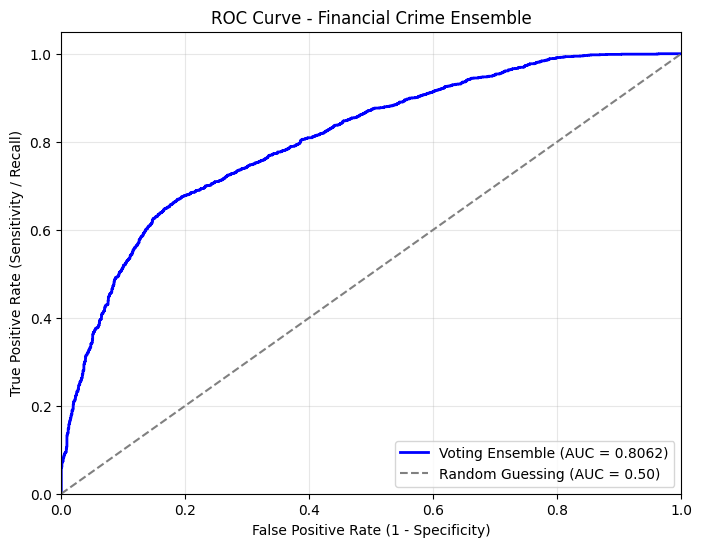

In [55]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'Voting Ensemble (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guessing (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('ROC Curve - Financial Crime Ensemble')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

### Threshold Manipulation

In [56]:
from sklearn.metrics import precision_recall_curve

In [57]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)

In [58]:
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)

In [59]:
best_idx = f1_scores.argmax()
best_threshold = thresholds[best_idx]

In [60]:
print(f"Optimal Threshold based on F1-Score: {best_threshold:.4f}")
print(f"Expected Precision at this threshold: {precisions[best_idx]:.4f}")
print(f"Expected Recall at this threshold: {recalls[best_idx]:.4f}")

Optimal Threshold based on F1-Score: 0.3184
Expected Precision at this threshold: 0.6349
Expected Recall at this threshold: 0.8759


### Apply the New Threshold

In [61]:
y_pred_optimized = (y_pred_proba >= best_threshold).astype(int)

In [62]:
print("Optimized Ensemble Performance:")
print(classification_report(y_test, y_pred_optimized))

Optimized Ensemble Performance:
              precision    recall  f1-score   support

           0       0.80      0.50      0.61      1975
           1       0.63      0.88      0.74      1975

    accuracy                           0.69      3950
   macro avg       0.72      0.69      0.67      3950
weighted avg       0.72      0.69      0.67      3950



##### Because the Class 1 F1-Score went up, the model became mathematically superior at catching financial crime.